# 09 · How do payment and coverage differ by neighborhood income?
**Venkat Repaka and Ritik Gaire · NFIP flood claims**

**Question:** do payments and coverage differ between richer and poorer neighborhoods?

We join the claims to Census income, compare simple averages, and then add controls one at a time. The answer changes with the controls, so we show the whole path and not one number.

**Learning bridge:** notebook 08 found low coverage among some claim groups. Census data let us study neighborhood context. We add one adjustment at a time, following the model-comparison reasoning from lecture 07. The explanatory statistics extend the course models and do not prove causation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df=load_joined()

### Step 1 · Define area income groups and verify matching
The unit is a neighborhood, not an individual policyholder.

In [2]:
acs=pd.read_parquet(DATA/'acs_blockgroups.parquet')
edges=acs.median_household_income.quantile([0,.2,.4,.6,.8,1]).to_numpy();edges[0],edges[-1]=-np.inf,np.inf
Q=['Q1 lowest','Q2','Q3','Q4','Q5 highest']
df['income_q']=pd.cut(df.median_household_income,edges,labels=Q).astype('string')
m=df[df.median_household_income.notna()].copy()
print(f'Matched income: {len(m):,} of {len(df):,} claims ({len(m)/len(df):.1%})')
display(df.groupby('loss_year').median_household_income.agg(lambda s:s.notna().mean()).to_frame('income match share'))
print('Income cutoffs:',np.round(edges[1:-1]).astype(int))

Matched income: 235,462 of 277,033 claims (85.0%)


,income match share
loss_year,
2020,0.757
2021,0.789
2022,0.838
2023,0.862
2024,0.906
2025,0.895


Income cutoffs: [ 52250  70536  90245 121667]


## 1. What the income groups mean
The groups divide US block groups with published income into five equal **numbers of areas**. They do not contain equal numbers of households, insured homes or homes exposed to flooding. Therefore, a claim share below 20% is not by itself evidence of lower insurance access.

ACS gives neighborhood averages, not claimant income. Five-year estimates also have sampling uncertainty. We do not use the available data to estimate an individual's income.

### Step 2 · Separate missing, zero and positive payments
Missing payments must not be silently counted as known zero payments.

In [3]:
m['zero_payment']=np.where(m.amountPaidOnBuildingClaim.notna(),m.amountPaidOnBuildingClaim.eq(0).astype(float),np.nan)
m['pay_ratio_raw']=m.amountPaidOnBuildingClaim/m.buildingDamageAmount.where(m.buildingDamageAmount>0)
m['pay_ratio']=m.pay_ratio_raw.clip(0,1.5)
itv=m.totalBuildingInsuranceCoverage/m.buildingReplacementCost.where(m.buildingReplacementCost>0)
m['low_below_cap']=np.where(m.occupancy.eq('11')&itv.notna(),(itv.lt(.8)&m.totalBuildingInsuranceCoverage.lt(249999)).astype(float),np.nan)

### Step 3 · Read unadjusted differences before explaining them
The raw differences mix location, building size, damage and insurance.

,claims,payment_known,zero_payment,pay_ratio,median_damage_ratio,low_coverage_single_family
income_q,,,,,,
Q1 lowest,31748,29428,0.170,0.872,0.171,0.310
Q2,43913,40645,0.163,0.873,0.169,0.238
Q3,48799,45266,0.161,0.882,0.173,0.174
Q4,56754,52278,0.162,0.881,0.143,0.128
Q5 highest,54248,50085,0.158,0.889,0.106,0.092


Payment/damage ratios above 1.5, capped for primary model: 5001


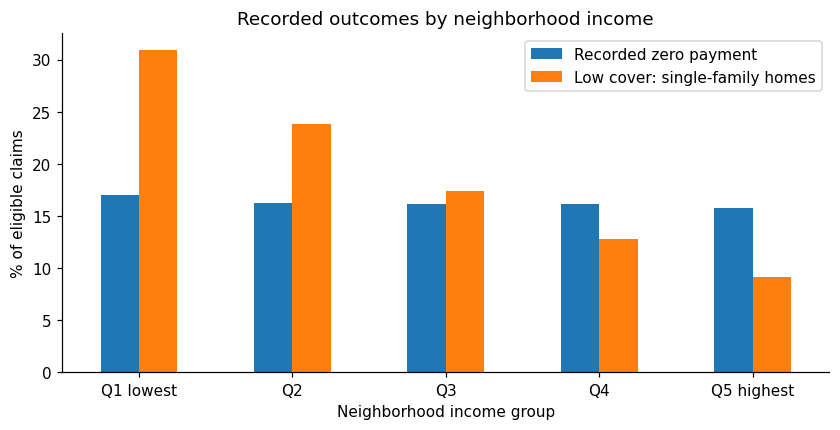

In [4]:
raw=m.groupby('income_q',observed=True).agg(claims=('id','size'),payment_known=('amountPaidOnBuildingClaim','count'),
    zero_payment=('zero_payment','mean'),pay_ratio=('pay_ratio','mean'),median_damage_ratio=('damage_ratio','median'),
    low_coverage_single_family=('low_below_cap','mean'))
display(raw.round(3));save_table(raw,'09_raw_income_groups')
print('Payment/damage ratios above 1.5, capped for primary model:',m.pay_ratio_raw.gt(1.5).sum())
raw[['zero_payment','low_coverage_single_family']].rename(columns={'zero_payment':'Recorded zero payment','low_coverage_single_family':'Low cover: single-family homes'}).mul(100).plot.bar(figsize=(9,4),title='Recorded outcomes by neighborhood income')
plt.ylabel('% of eligible claims');plt.xlabel('Neighborhood income group');plt.xticks(rotation=0);plt.show()

## 2. Adjustment models: what changes the income gap?
We model payment ÷ damage among claims with positive damage, recorded payment and a usable damage ratio. The models compare the highest and lowest income groups while holding measured inputs fixed.

| Model | Added information |
|---|---|
| A | Damage-ratio band, building age, foundation, occupancy, zone, state and event (unnamed events are split by year) |
| B | A + coverage/replacement-cost band and deductible band |
| C | B + log damage dollars |
| D | B + a flexible curve for log damage dollars |
| E | D + rainfall and hurricane-track exposure |

A fixed deductible is a larger share of a small dollar loss. This is one possible explanation for a payment-share gap. A gap shrinking after adjustment supports that explanation, but does not prove it or rule out differences in claim handling. Broad state and event controls are not the same as matching exact places.

We use ordinary least squares for clear adjusted contrasts. One category is left out from each input group, avoiding duplicate category columns. We allow related claims within an event–neighborhood group when estimating uncertainty.

### Step 4 · Set up the adjustment definitions
We use one common outcome population for A–E so that the model comparison is not just a change of rows. The functions define design columns and the same event–neighborhood uncertainty calculation.

In [5]:
import statsmodels.api as sm
from patsy import dmatrix
m['storm']=m.floodEvent.fillna('unnamed-'+m.loss_year.astype(str))
m['itv_band']=pd.cut(itv,[-np.inf,.5,.8,1,np.inf],labels=['under50','50to80','80to100','over100']).astype('string').fillna('unknown')
m['deductible_band']=pd.cut(m.deductible_usd,[-np.inf,1000,1500,2000,5000,np.inf]).astype('string').fillna('unknown')
p=m[m.pay_ratio.notna()&m.severity_band.notna()].copy()
# Filling these explanatory covariates uses the analysis sample; there is no prediction test here.
p['building_age']=p.building_age.fillna(p.building_age.median())
p['log_damage']=np.log10(p.buildingDamageAmount)
p['year_code']=p.loss_year.astype(int).astype(str)
for cc in ['income_q','severity_band','itv_band','deductible_band']:
    p[cc]=p[cc].astype(str)
for cc in ['rain_5d_mm','trk_dist_km','trk_wind_kt']:
    p[cc+'_was_missing']=p[cc].isna().astype(float)
    p[cc]=p[cc].fillna(p[cc].median())
base="C(income_q, Treatment(reference='Q1 lowest')) + C(severity_band) + building_age + C(foundation) + C(occupancy) + C(zone) + C(state) + C(storm)"
insurance=' + C(itv_band) + C(deductible_band)'
formulas={'A':base,'B':base+insurance,'C':base+insurance+' + log_damage',
          'D':base+insurance+' + bs(log_damage, df=5, degree=3)',
          'E':base+insurance+' + bs(log_damage, df=5, degree=3) + rain_5d_mm + trk_dist_km + trk_wind_kt + rain_5d_mm_was_missing + trk_dist_km_was_missing + trk_wind_kt_was_missing'}
fits={};designs={};rows=[]
groups=neighborhood_groups(p)
def fit_adjustment(name):
    formula=formulas[name]
    X=dmatrix(formula,p,return_type='dataframe')
    fit=sm.OLS(p.pay_ratio.to_numpy(),X).fit(cov_type='cluster',cov_kwds={'groups':groups.to_numpy()})
    term=next(c for c in X if 'income_q' in c and 'Q5 highest' in c)
    ci=fit.conf_int().loc[term]*100
    rows.append({'model':name,'gap Q5 minus Q1 (points)':fit.params[term]*100,'95% low':ci.iloc[0],'95% high':ci.iloc[1],
                 'R2 explanatory':fit.rsquared,'claims':len(p)})
    fits[name]=fit;designs[name]=X
    return pd.DataFrame(rows).set_index('model')

### Adjustment A · One change at a time
Start with damage-ratio bands, buildings and event/place. This is a measured comparison, not exact matching at the same flood depth.

In [6]:
result=fit_adjustment('A')
display(result.round(3))

,gap Q5 minus Q1 (points),95% low,95% high,R2 explanatory,claims
model,,,,,
A,2.654,2.001,3.306,0.223,176343


### Adjustment B · One change at a time
Add coverage and deductible bands. If the contrast changes, insurance measures account for part of this fitted difference; that does not establish an owner motive.

In [7]:
result=fit_adjustment('B')
display(result.round(3))

,gap Q5 minus Q1 (points),95% low,95% high,R2 explanatory,claims
model,,,,,
A,2.654,2.001,3.306,0.223,176343
B,2.585,1.960,3.211,0.307,176343


### Adjustment C · One change at a time
Add a straight-line log dollar-damage term. A fixed deductible takes a larger share of a small claim, so loss size is a plausible missing factor.

In [8]:
result=fit_adjustment('C')
display(result.round(3))

,gap Q5 minus Q1 (points),95% low,95% high,R2 explanatory,claims
model,,,,,
A,2.654,2.001,3.306,0.223,176343
B,2.585,1.960,3.211,0.307,176343
C,-0.109,-0.672,0.454,0.491,176343


**Checkpoint · What the result changes**

The income contrast changes from **2.65 points** in A to **-0.11** in C. Dollar loss size matters in this model. Before declaring the difference explained, we challenge the straight-line damage adjustment.

### Adjustment D · One change at a time
Challenge the straight-line assumption with a flexible damage curve. If the contrast changes again, the claim that the gap disappeared was model-dependent.

In [9]:
result=fit_adjustment('D')
display(result.round(3))

,gap Q5 minus Q1 (points),95% low,95% high,R2 explanatory,claims
model,,,,,
A,2.654,2.001,3.306,0.223,176343
B,2.585,1.960,3.211,0.307,176343
C,-0.109,-0.672,0.454,0.491,176343
D,0.819,0.345,1.294,0.549,176343


**Checkpoint · What the result changes**

The flexible damage adjustment gives an income contrast of **0.82 points** in D. The answer changes under a reasonable model choice. We discard a definitive equal-treatment conclusion and next test whether broad event exposure changes this estimate.

### Adjustment E · One change at a time
Add broad rain and track exposure. This asks whether those external conditions explain more of the measured contrast, while preserving their location and timing limits.

In [10]:
result=fit_adjustment('E')
display(result.round(3))

,gap Q5 minus Q1 (points),95% low,95% high,R2 explanatory,claims
model,,,,,
A,2.654,2.001,3.306,0.223,176343
B,2.585,1.960,3.211,0.307,176343
C,-0.109,-0.672,0.454,0.491,176343
D,0.819,0.345,1.294,0.549,176343
E,0.763,0.289,1.237,0.549,176343


### Step 5 · Compare the full path, including uncertainty
The graph makes the changes across A–E visible. Confidence intervals are conditional on the data and model assumptions. They do not prove that unmeasured claim processes are equal.

,gap Q5 minus Q1 (points),95% low,95% high,R2 explanatory,claims
model,,,,,
A,2.654,2.001,3.306,0.223,176343
B,2.585,1.960,3.211,0.307,176343
C,-0.109,-0.672,0.454,0.491,176343
D,0.819,0.345,1.294,0.549,176343
E,0.763,0.289,1.237,0.549,176343


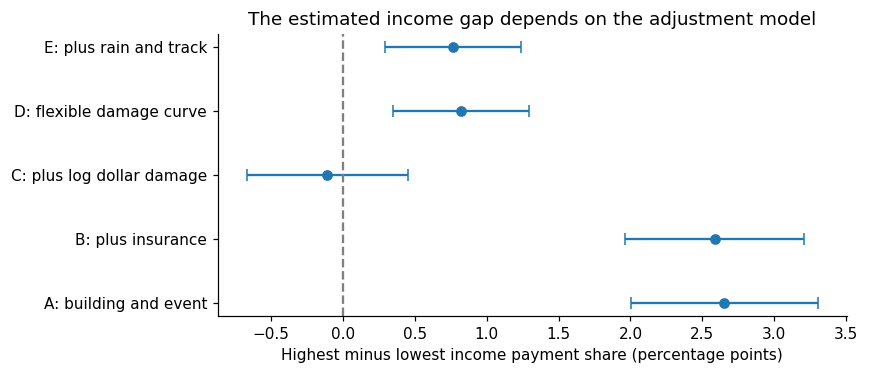

In [11]:
result=pd.DataFrame(rows).set_index('model');display(result.round(3));save_table(result,'09_adjusted_income_gap')
fig,ax=plt.subplots(figsize=(8,3.5))
value=result['gap Q5 minus Q1 (points)']
ax.errorbar(value,np.arange(len(result)),xerr=np.vstack([value-result['95% low'],result['95% high']-value]),fmt='o',capsize=4)
ax.set_yticks(np.arange(len(result)),['A: building and event','B: plus insurance','C: plus log dollar damage','D: flexible damage curve','E: plus rain and track'])
ax.axvline(0,color='gray',ls='--');ax.set(xlabel='Highest minus lowest income payment share (percentage points)',title='The estimated income gap depends on the adjustment model')
plt.tight_layout();plt.show()

## 3. Sensitivity checks
We check whether capping payment shares or excluding ratios above 1 changes the result. We also remove each major storm in turn. These checks expose dependence on the outcome definition and event mix.

The intervals account for event–neighborhood groups. They remain conditional on the storms and model assumptions in this dataset. Unmeasured local conditions and a common storm-wide effect can add uncertainty.

In [12]:
X=designs['D'];term=next(c for c in X if 'income_q' in c and 'Q5 highest' in c)
checks=[]
# A deductible is subtracted from every payment, so small claims look 'less paid' by construction.
# This outcome adds the deductible back before dividing by damage.
deductible_adjusted=((p.amountPaidOnBuildingClaim+p.deductible_usd.fillna(0))/p.buildingDamageAmount.where(p.buildingDamageAmount>0)).clip(0,1.5)
variants=[('primary cap 1.5',np.ones(len(p),bool),p.pay_ratio),
          ('deductible added back (cap 1.5)',deductible_adjusted.notna().to_numpy(),deductible_adjusted.fillna(0)),
          ('uncapped payment share',np.ones(len(p),bool),p.pay_ratio_raw),
          ('shares at most 1',p.pay_ratio_raw.le(1).to_numpy(),p.pay_ratio_raw)]
variants += [(f'without {s}',p.floodEvent.ne(s).to_numpy(),p.pay_ratio) for s in ['Hurricane Helene','Hurricane Ian','Hurricane Ida']]
for label,mask,outcome in variants:
    fit=sm.OLS(outcome.iloc[np.flatnonzero(mask)].to_numpy(),X.iloc[np.flatnonzero(mask)]).fit()
    checks.append({'check':label,'claims':mask.sum(),'gap points':fit.params[term]*100})
sensitivity=pd.DataFrame(checks).set_index('check');display(sensitivity.round(3));save_table(sensitivity,'09_income_sensitivity')

,claims,gap points
check,,
primary cap 1.5,176343,0.819
deductible added back (cap 1.5),176343,0.158
uncapped payment share,176343,4.103
shares at most 1,136647,1.000
without Hurricane Helene,132796,0.269
without Hurricane Ian,147745,0.791
without Hurricane Ida,158922,0.880


**How to read these checks.** The gap depends on how we define the payment share. A payment is the damage minus the deductible, so a fixed deductible takes a bigger bite out of small claims. The row "deductible added back" removes this effect, and the gap drops to about 0.2 points. This suggests that most of the small gap is a deductible effect. The "uncapped" row keeps a few very large ratios, which is why it moves so much. A reader should trust the *range* of answers, not one number.

The raw table also shows a large gap in **low coverage**: about three in ten single-family claims in the lowest-income areas have low coverage, against about one in ten in the highest-income areas. This gap is not explained by the payment models above. It is a separate result about how much insurance people hold.

## 4. Recorded zero payments
We report the zero-payment rate only among claims with a known payment value. Missing payments are counted separately. A recorded zero does not establish closure, denial or an unfair decision. The income comparison alone cannot explain the reasons.

In [13]:
nonpayment=m.groupby('income_q',observed=True).agg(claims=('id','size'),missing_payment=('amountPaidOnBuildingClaim',lambda s:s.isna().sum()),
    zero_payment_known=('zero_payment','mean'))
display(nonpayment.round(3))
reasons=m[m.amountPaidOnBuildingClaim.eq(0)].copy()
reasons['reason_code']=reasons.nonPaymentReasonBuilding.astype('string').fillna('not recorded')
top=reasons.reason_code.value_counts().head(6).index
reasons['reason_code']=reasons.reason_code.where(reasons.reason_code.isin(top),'other')
display(pd.crosstab(reasons.income_q,reasons.reason_code,normalize='index').round(3))

,claims,missing_payment,zero_payment_known
income_q,,,
Q1 lowest,31748,2320,0.170
Q2,43913,3268,0.163
Q3,48799,3533,0.161
Q4,56754,4476,0.162
Q5 highest,54248,4163,0.158


reason_code,01,06,20,97,99,not recorded,other
income_q,,,,,,,
Q1 lowest,0.162,0.256,0.095,0.142,0.162,0.136,0.047
Q2,0.196,0.205,0.109,0.138,0.178,0.122,0.052
Q3,0.193,0.200,0.115,0.130,0.180,0.131,0.050
Q4,0.179,0.177,0.122,0.148,0.180,0.148,0.046
Q5 highest,0.162,0.173,0.113,0.157,0.177,0.170,0.049


## 5. Answer and limits
The raw table shows the observed payment and coverage differences. Models A–E show how the estimated income contrast changes after accounting for measured loss size, insurance and event exposure. Sensitivity to those choices is part of the result.

If a gap becomes small, the correct conclusion is “the adjusted payment-share gap is small under this model.” It is not proof that claims were handled equally. Damage is recorded through the claims process and may itself be measured differently; adjusting for it can hide some differences.

Income is measured for neighborhoods, Census matches are incomplete, and only insured claimants appear. We do not observe household finances, other insurance, claim disputes, actual flood depth or all policy rules. These limits prevent a strong conclusion about fairness or the reason for low coverage.

In [14]:
a=result.loc['A','gap Q5 minus Q1 (points)'];e=result.loc['E','gap Q5 minus Q1 (points)']
display(Markdown(f"**Observed adjusted contrast.** The estimated highest-minus-lowest income gap changes from **{a:.2f} points** in A "
                 f"to **{e:.2f} points** in E. The interval and sensitivity tables show the precision and model dependence. "
                 "This result describes measured associations, not a finding about equal treatment."))

**Observed adjusted contrast.** The estimated highest-minus-lowest income gap changes from **2.65 points** in A to **0.76 points** in E. The interval and sensitivity tables show the precision and model dependence. This result describes measured associations, not a finding about equal treatment.

### Decision ledger
We kept the raw group comparison as a starting point, then added measured controls one at a time. We discarded a definitive equal-treatment claim because the contrast depends on the damage adjustment and unmeasured factors remain. Model C and D are both reported so a convenient specification cannot decide the story alone.

### Result in plain English

The estimated highest-minus-lowest income payment-share gap is **2.65 points** in model A, **-0.11** after the straight-line log-damage adjustment in C, and **0.76** with the flexible damage curve and event exposure in E.

When the deductible is added back to the payment, the gap is only **0.16** points. So the gap changes with the model, and most of what is left looks like a deductible effect. This does not prove that claims are handled equally: we only see neighborhood averages, some Census matches are missing, and we cannot see the claim process.